In [3]:

# text classification with linear models
# Dataset: NLTK Movie Reviews

# STEP 1: IMPORT LIBRARIES

import nltk
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.corpus import movie_reviews

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_recall_fscore_support,
    average_precision_score,
    f1_score
)

# Download the dataset
nltk.download('movie_reviews')
nltk.download('punkt', quiet=True)


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


True

In [4]:


# STEP 2: LOAD THE DATASET

documents = []
labels = []

for fileid in movie_reviews.fileids():

    # Get the review text
    text = movie_reviews.raw(fileid)

    # Get the category: pos or neg
    label = movie_reviews.categories(fileid)[0]

    documents.append(text)
    labels.append(label)

documents = np.array(documents)
labels = np.array(labels)

print("Dataset loaded successfully!")
print("Total documents:", len(documents))
print("Positive reviews:", sum(labels == "pos"))
print("Negative reviews:", sum(labels == "neg"))



Dataset loaded successfully!
Total documents: 2000
Positive reviews: 1000
Negative reviews: 1000


In [5]:

# STEP 3: PREPROCESS THE TEXT

def preprocess(text):

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


clean_documents = [preprocess(doc) for doc in documents]


In [6]:


# STEP 4: SPLIT DATA INTO TRAINING, DEVELOPMENT AND TEST SETS

# First: 70% training, 30% remaining
X_train, X_remaining, y_train, y_remaining = train_test_split(
    clean_documents,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second: Divide remaining data into 15% development and 15% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining
)

print("\nDATASET SPLIT")
print("Training documents:", len(X_train))
print("Development documents:", len(X_dev))
print("Test documents:", len(X_test))




DATASET SPLIT
Training documents: 1400
Development documents: 300
Test documents: 300


In [7]:

from itertools import product

class_names = ['neg', 'pos']
C_values = [0.01, 0.1, 1, 10, 100]

feature_grid = {
    'ngram_range': [(1, 1), (1, 2), (1, 3)],
    'min_df': [2, 5],
    'max_features': [5000, 10000, None],
}

best_config, best_C, best_dev_f1 = None, None, -1
tuning_log = []

for ngram, min_df, max_feat in product(
        feature_grid['ngram_range'],
        feature_grid['min_df'],
        feature_grid['max_features']):

    vec = TfidfVectorizer(ngram_range=ngram, min_df=min_df,
                          max_features=max_feat, sublinear_tf=True)
    Xtr = vec.fit_transform(X_train)   # fit on training data only
    Xdv = vec.transform(X_dev)

    for C in C_values:
        m = LogisticRegression(C=C, max_iter=1000, random_state=42)
        m.fit(Xtr, y_train)
        f1 = f1_score(y_dev, m.predict(Xdv), labels=class_names, average='macro')
        tuning_log.append((ngram, min_df, max_feat, C, round(f1, 4)))

        if f1 > best_dev_f1:
            best_dev_f1, best_C = f1, C
            best_config = dict(ngram_range=ngram, min_df=min_df, max_features=max_feat)

print("Best features:", best_config, "| Best C:", best_C,
      "| Dev macro F1:", round(best_dev_f1, 4))

# Refit the winning vectorizer, then continue with your Step 6 onward
vectorizer = TfidfVectorizer(sublinear_tf=True, **best_config)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)
X_test_tfidf = vectorizer.transform(X_test)


Best features: {'ngram_range': (1, 2), 'min_df': 5, 'max_features': 10000} | Best C: 10 | Dev macro F1: 0.8833


In [8]:
import pandas as pd

log = pd.DataFrame(tuning_log,
                   columns=['ngram_range', 'min_df', 'max_features', 'C', 'dev_macro_F1'])

# 1. The 10 best configurations
print(log.sort_values('dev_macro_F1', ascending=False).head(10).to_string())

# 2. Best score for each feature limit (is 5,000 worse than 10,000?)
print(log.groupby('max_features', dropna=False)['dev_macro_F1'].max())

# 3. Best score for each C (does stronger regularisation help?)
print(log.groupby('C')['dev_macro_F1'].max())

   ngram_range  min_df  max_features      C  dev_macro_F1
53      (1, 2)       5       10000.0   10.0        0.8833
38      (1, 2)       2       10000.0   10.0        0.8800
83      (1, 3)       5       10000.0   10.0        0.8800
54      (1, 2)       5       10000.0  100.0        0.8766
39      (1, 2)       2       10000.0  100.0        0.8766
84      (1, 3)       5       10000.0  100.0        0.8766
68      (1, 3)       2       10000.0   10.0        0.8733
69      (1, 3)       2       10000.0  100.0        0.8733
3       (1, 1)       2        5000.0   10.0        0.8700
14      (1, 1)       2           NaN  100.0        0.8700
max_features
5000.0     0.8700
10000.0    0.8833
NaN        0.8700
Name: dev_macro_F1, dtype: float64
C
0.01      0.8399
0.10      0.8399
1.00      0.8567
10.00     0.8833
100.00    0.8766
Name: dev_macro_F1, dtype: float64


In [9]:

# STEP 6: DATASET STATISTICS

all_words = [len(doc.split()) for doc in clean_documents]

print("\nDATASET STATISTICS")
print("---------------------------")
print("Total documents:", len(documents))
print("Average document length:", round(np.mean(all_words), 2))
print("Training documents:", len(X_train))
print("Development documents:", len(X_dev))
print("Test documents:", len(X_test))
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Number of features:", X_train_tfidf.shape[1])




DATASET STATISTICS
---------------------------
Total documents: 2000
Average document length: 665.64
Training documents: 1400
Development documents: 300
Test documents: 300
Vocabulary size: 10000
Number of features: 10000


In [10]:

# STEP 7: TRAIN THE MAJORITY CLASSIFIER

# The majority classifier always predicts
# the most frequent class in the training data.

majority_class = pd.Series(y_train).mode()[0]

print("\nMajority class:", majority_class)


def majority_predictions(number_of_documents):

    return np.array([majority_class] * number_of_documents)


def majority_probabilities(number_of_documents):

    # Constant probability scores for the majority class
    probabilities = np.zeros((number_of_documents, 2))

    majority_index = list(class_names).index(majority_class)

    probabilities[:, majority_index] = 1.0

    return probabilities



Majority class: neg


In [11]:

# STEP 9: TRAIN FINAL LOGISTIC REGRESSION MODEL

logistic_model = LogisticRegression(
    C=best_C,
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)



LogisticRegression(C=10, max_iter=1000, random_state=42)

In [12]:

# STEP 10: EVALUATION FUNCTION

def evaluate_classifier(y_true, predictions, probabilities):

    results = {}

    # Calculate metrics for each class
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        predictions,
        labels=class_names,
        zero_division=0
    )

    for i, class_name in enumerate(class_names):

        # Convert the true labels into binary labels
        binary_labels = (np.array(y_true) == class_name).astype(int)

        # Calculate Precision-Recall AUC
        pr_auc = average_precision_score(
            binary_labels,
            probabilities[:, i]
        )

        results[class_name] = {
            'Precision': precision[i],
            'Recall': recall[i],
            'F1': f1[i],
            'PR-AUC': pr_auc
        }

    # Calculate macro averages
    results['Macro'] = {
        'Precision': np.mean(precision),
        'Recall': np.mean(recall),
        'F1': np.mean(f1),
        'PR-AUC': np.mean([
            results[c]['PR-AUC'] for c in class_names
        ])
    }

    return results


In [13]:


# STEP 11: EVALUATE BOTH CLASSIFIERS

classifiers = {
    'Majority Classifier': None,
    'Logistic Regression': logistic_model
}

datasets = {
    'Training': (X_train_tfidf, y_train),
    'Development': (X_dev_tfidf, y_dev),
    'Test': (X_test_tfidf, y_test)
}

all_results = {}

for dataset_name, (X, y) in datasets.items():

    all_results[dataset_name] = {}

    for classifier_name, model in classifiers.items():

        if classifier_name == 'Majority Classifier':

            predictions = majority_predictions(len(y))
            probabilities = majority_probabilities(len(y))

        else:

            predictions = model.predict(X)

            probabilities = model.predict_proba(X)

            # Ensure probability columns follow class_names order
            order = [
                list(model.classes_).index(c)
                for c in class_names
            ]

            probabilities = probabilities[:, order]

        results = evaluate_classifier(
            y,
            predictions,
            probabilities
        )

        all_results[dataset_name][classifier_name] = results


In [14]:


# STEP 12: DISPLAY THREE RESULT TABLES

def create_results_table(dataset_name):

    rows = []

    for classifier_name in classifiers.keys():

        results = all_results[dataset_name][classifier_name]

        row = {'Classifier': classifier_name}

        # Add class-specific results
        for class_name in class_names:

            for metric in ['Precision', 'Recall', 'F1', 'PR-AUC']:

                column_name = class_name + ' ' + metric

                row[column_name] = results[class_name][metric]

        # Add macro results
        for metric in ['Precision', 'Recall', 'F1', 'PR-AUC']:

            row['Macro ' + metric] = results['Macro'][metric]

        rows.append(row)

    table = pd.DataFrame(rows)

    # Round values to four decimal places
    return table.round(4)


print("TRAINING RESULTS")


training_table = create_results_table('Training')
display(training_table)


print("DEVELOPMENT RESULTS")


development_table = create_results_table('Development')
display(development_table)


print("TEST RESULTS")


test_table = create_results_table('Test')
display(test_table)



TRAINING RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5,1.0,0.6667,0.5,0.0,0.0,0.0,0.5,0.25,0.5,0.3333,0.5
1,Logistic Regression,1.0,1.0,1.0000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0000,1.0


DEVELOPMENT RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5000,1.0000,0.6667,0.500,0.0000,0.0000,0.0000,0.5000,0.2500,0.5000,0.3333,0.5000
1,Logistic Regression,0.8912,0.8733,0.8822,0.941,0.8758,0.8933,0.8845,0.9469,0.8835,0.8833,0.8833,0.9439


TEST RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.500,1.0000,0.6667,0.5000,0.0000,0.0000,0.0000,0.5000,0.2500,0.5000,0.3333,0.5000
1,Logistic Regression,0.859,0.8933,0.8758,0.9386,0.8889,0.8533,0.8707,0.9532,0.8739,0.8733,0.8733,0.9459


In [15]:

# STEP 13: LEARNING CURVES


percentages = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

learning_results = {
    'Majority Classifier': {
        'train': [],
        'dev': []
    },
    'Logistic Regression': {
        'train': [],
        'dev': []
    }
}

for percentage in percentages:

    # Number of training documents to use
    number = max(2, int(len(X_train) * percentage / 100))

    # Get a stratified subset of the training data
    if percentage == 100:
      X_subset = X_train_tfidf
      y_subset = y_train
    else:
         X_subset, _, y_subset, _ = train_test_split(
        X_train_tfidf,
        y_train,
        train_size=number,
        random_state=42,
        stratify=y_train
    )


    # MAJORITY CLASSIFIER


    subset_majority = pd.Series(y_subset).mode()[0]

    train_predictions = np.array(
        [subset_majority] * len(y_subset)
    )

    dev_predictions = np.array(
        [subset_majority] * len(y_dev)
    )

    train_f1 = f1_score(
        y_subset,
        train_predictions,
        labels=class_names,
        average='macro',
        zero_division=0
    )

    dev_f1 = f1_score(
        y_dev,
        dev_predictions,
        labels=class_names,
        average='macro',
        zero_division=0
    )

    learning_results['Majority Classifier']['train'].append(train_f1)
    learning_results['Majority Classifier']['dev'].append(dev_f1)


    # LOGISTIC REGRESSION


    temporary_model = LogisticRegression(
        C=best_C,
        max_iter=1000,
        random_state=42
    )

    temporary_model.fit(X_subset, y_subset)

    train_predictions = temporary_model.predict(X_subset)
    dev_predictions = temporary_model.predict(X_dev_tfidf)

    train_f1 = f1_score(
        y_subset,
        train_predictions,
        labels=class_names,
        average='macro'
    )

    dev_f1 = f1_score(
        y_dev,
        dev_predictions,
        labels=class_names,
        average='macro'
    )

    learning_results['Logistic Regression']['train'].append(train_f1)
    learning_results['Logistic Regression']['dev'].append(dev_f1)



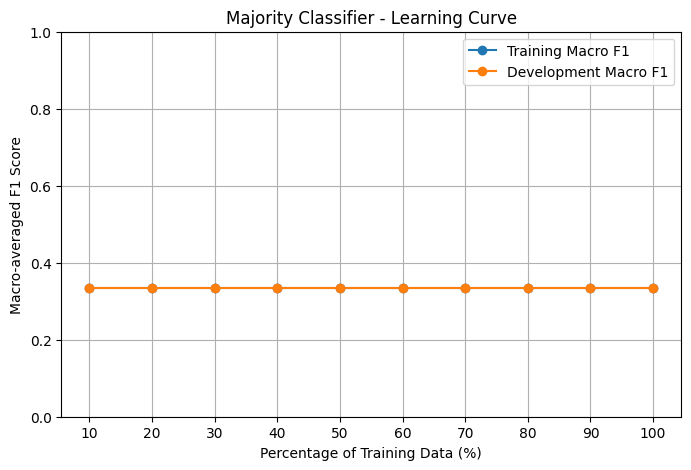

{'Majority Classifier': {'train': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333], 'dev': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333]}, 'Logistic Regression': {'train': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'dev': [0.7566423308997566, 0.8099472075576549, 0.8466598515489577, 0.8499182888461496, 0.8599439775910365, 0.8599937775012223, 0.8666133119914632, 0.8699869986998701, 0.8633196652998634, 0.8833216654998833]}}


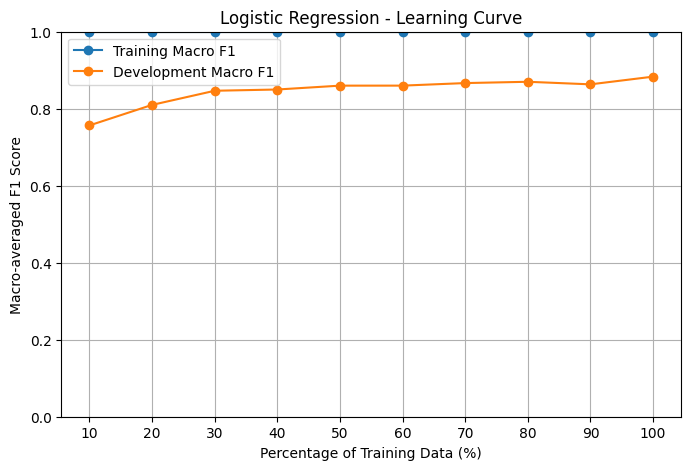

{'Majority Classifier': {'train': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333], 'dev': [0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333, 0.3333333333333333]}, 'Logistic Regression': {'train': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'dev': [0.7566423308997566, 0.8099472075576549, 0.8466598515489577, 0.8499182888461496, 0.8599439775910365, 0.8599937775012223, 0.8666133119914632, 0.8699869986998701, 0.8633196652998634, 0.8833216654998833]}}


In [16]:

# STEP 14: TWO LEARNING CURVES

for classifier_name in classifiers.keys():

    plt.figure(figsize=(8, 5))

    plt.plot(
        percentages,
        learning_results[classifier_name]['train'],
        marker='o',
        label='Training Macro F1'
    )

    plt.plot(
        percentages,
        learning_results[classifier_name]['dev'],
        marker='o',
        label='Development Macro F1'
    )

    plt.title(classifier_name + ' - Learning Curve')

    plt.xlabel('Percentage of Training Data (%)')

    plt.ylabel('Macro-averaged F1 Score')

    plt.ylim(0, 1)

    plt.xticks(percentages)

    plt.grid(True)

    plt.legend()

    plt.show()
    print(learning_results)



In [17]:
# ============================================================
# EXERCISE 4: MLP SENTIMENT CLASSIFIER IN PYTORCH
# Continue in the SAME notebook as exercise 9 of Part 2, after the
# cell that builds the three results tables (old Step 12).
# Each "CELL n" block below goes into its own Colab cell, in order.
# It reuses: X_train/X_dev/X_test (cleaned text), y_train/y_dev/y_test,
# vectorizer, X_*_tfidf, class_names, all_results, evaluate_classifier,
# preprocess, best_config, best_C.
# ============================================================


# ===== CELL 1: imports, seed, tensors =====

import copy
import itertools
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

label_to_id = {c: i for i, c in enumerate(class_names)}   # neg -> 0, pos -> 1

def sparse_to_tensor(X_sparse):
    return torch.tensor(X_sparse.toarray(), dtype=torch.float32).to(device)

def labels_to_tensor(y):
    return torch.tensor([label_to_id[c] for c in y], dtype=torch.long).to(device)

# Same TF-IDF features as the logistic regression (chosen on the dev set in exercise 9)
Xtr_t, Xdv_t, Xte_t = (sparse_to_tensor(X_train_tfidf),
                       sparse_to_tensor(X_dev_tfidf),
                       sparse_to_tensor(X_test_tfidf))
ytr_t, ydv_t, yte_t = (labels_to_tensor(y_train),
                       labels_to_tensor(y_dev),
                       labels_to_tensor(y_test))

print("Input dimension:", Xtr_t.shape[1])



Device: cpu
Input dimension: 10000


In [18]:

# ===== CELL 2: the MLP, training loop, helper functions =====

class MLP(nn.Module):
    """Fully connected network: n_layers x (Linear, ReLU, Dropout), then a Linear output layer."""

    def __init__(self, in_dim, hidden, n_layers, dropout, n_classes=2):
        super().__init__()
        layers = []
        dim = in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(dim, hidden), nn.ReLU(), nn.Dropout(dropout)]
            dim = hidden
        layers.append(nn.Linear(dim, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def eval_loss(model, X, y):
    # Cross-entropy of the whole subset, dropout switched off
    model.eval()
    with torch.no_grad():
        return F.cross_entropy(model(X), y).item()


def predict_proba(model, X):
    # Columns follow class_names order: [neg, pos]
    model.eval()
    with torch.no_grad():
        return F.softmax(model(X), dim=1).cpu().numpy()


def labels_from_probs(probs):
    return np.array(class_names)[probs.argmax(axis=1)]


def train_mlp(cfg, max_epochs=30, keep_k=1, batch_size=32, seed=SEED):
    """Train for max_epochs. After every epoch, record the training and development loss and
    remember the keep_k checkpoints with the lowest development loss."""
    torch.manual_seed(seed)
    model = MLP(Xtr_t.shape[1], cfg['hidden'], cfg['layers'], cfg['dropout']).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])

    history = {'train_loss': [], 'dev_loss': []}
    best = []                      # list of (dev_loss, epoch, state_dict), lowest dev loss first
    n = Xtr_t.shape[0]

    for epoch in range(1, max_epochs + 1):
        model.train()
        order = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = F.cross_entropy(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            optimizer.step()

        train_loss = eval_loss(model, Xtr_t, ytr_t)
        dev_loss = eval_loss(model, Xdv_t, ydv_t)
        history['train_loss'].append(train_loss)
        history['dev_loss'].append(dev_loss)

        state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best.append((dev_loss, epoch, state))
        best.sort(key=lambda item: item[0])
        best = best[:keep_k]

    return model, history, best


In [19]:


# ===== CELL 3: tune hyper-parameters on the development subset =====
# Criterion: macro F1 on the dev subset, at the epoch with the lowest dev loss.
# Takes a few minutes on CPU.

grid = {
    'layers':  [1, 2],
    'hidden':  [128, 256],
    'dropout': [0.3, 0.6],
    'lr':      [1e-3, 3e-4],
}

tuning_rows = []
for layers, hidden, dropout, lr in itertools.product(grid['layers'], grid['hidden'],
                                                     grid['dropout'], grid['lr']):
    cfg = {'layers': layers, 'hidden': hidden, 'dropout': dropout, 'lr': lr}
    model, history, best = train_mlp(cfg, max_epochs=30, keep_k=1)
    dev_loss, best_epoch, state = best[0]
    model.load_state_dict(state)
    dev_probs = predict_proba(model, Xdv_t)
    dev_f1 = f1_score(y_dev, labels_from_probs(dev_probs), labels=class_names, average='macro')
    tuning_rows.append({**cfg, 'best_epoch': best_epoch,
                        'dev_loss': round(dev_loss, 4), 'dev_macro_F1': round(dev_f1, 4)})
    print(cfg, '| best epoch', best_epoch, '| dev loss', round(dev_loss, 4),
          '| dev macro F1', round(dev_f1, 4))

tuning_mlp = pd.DataFrame(tuning_rows).sort_values(['dev_macro_F1', 'dev_loss'],
                                                   ascending=[False, True])
print("\nAll configurations, best first:")
print(tuning_mlp.to_string(index=False))

top = tuning_mlp.iloc[0]
best_cfg = {'layers': int(top['layers']), 'hidden': int(top['hidden']),
            'dropout': float(top['dropout']), 'lr': float(top['lr'])}
print("\nBest configuration:", best_cfg)



{'layers': 1, 'hidden': 128, 'dropout': 0.3, 'lr': 0.001} | best epoch 7 | dev loss 0.3247 | dev macro F1 0.87
{'layers': 1, 'hidden': 128, 'dropout': 0.3, 'lr': 0.0003} | best epoch 18 | dev loss 0.3202 | dev macro F1 0.87
{'layers': 1, 'hidden': 128, 'dropout': 0.6, 'lr': 0.001} | best epoch 7 | dev loss 0.315 | dev macro F1 0.8766
{'layers': 1, 'hidden': 128, 'dropout': 0.6, 'lr': 0.0003} | best epoch 23 | dev loss 0.3179 | dev macro F1 0.8767
{'layers': 1, 'hidden': 256, 'dropout': 0.3, 'lr': 0.001} | best epoch 4 | dev loss 0.3228 | dev macro F1 0.8699
{'layers': 1, 'hidden': 256, 'dropout': 0.3, 'lr': 0.0003} | best epoch 10 | dev loss 0.3206 | dev macro F1 0.8667
{'layers': 1, 'hidden': 256, 'dropout': 0.6, 'lr': 0.001} | best epoch 6 | dev loss 0.3174 | dev macro F1 0.8733
{'layers': 1, 'hidden': 256, 'dropout': 0.6, 'lr': 0.0003} | best epoch 15 | dev loss 0.3192 | dev macro F1 0.8666
{'layers': 2, 'hidden': 128, 'dropout': 0.3, 'lr': 0.001} | best epoch 2 | dev loss 0.345 | d

Epoch with the lowest development loss: 23 | dev loss: 0.3179
The 5 best epochs (by dev loss): [19, 20, 22, 23, 24]


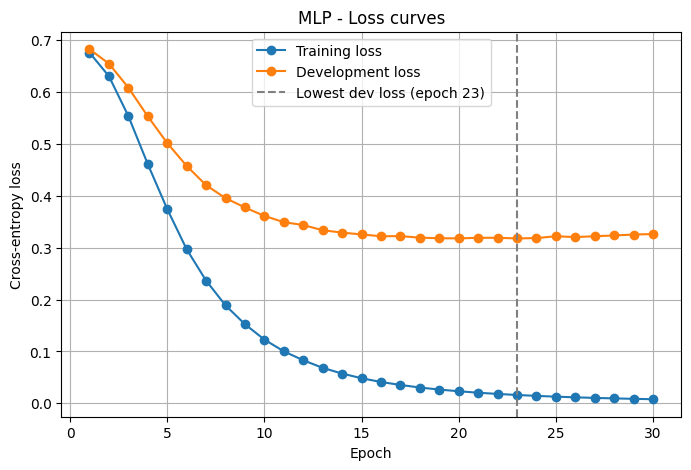


Epoch | train loss | dev loss
1 0.6761 0.6826
2 0.6307 0.6549
3 0.5538 0.6086
4 0.4612 0.5532
5 0.3746 0.5018
6 0.297 0.4576
7 0.2366 0.4206
8 0.1888 0.3955
9 0.1524 0.3775
10 0.1229 0.3612
11 0.1002 0.3492
12 0.083 0.3437
13 0.0683 0.3336
14 0.0573 0.3291
15 0.0483 0.3255
16 0.0411 0.3221
17 0.0354 0.3223
18 0.0305 0.3193
19 0.0265 0.3182
20 0.0233 0.318
21 0.0204 0.3191
22 0.0181 0.3191
23 0.0161 0.3179
24 0.0143 0.3186
25 0.0128 0.322
26 0.0115 0.3205
27 0.0104 0.3221
28 0.0095 0.3236
29 0.0086 0.3253
30 0.0079 0.3263


In [20]:

# ===== CELL 4: final training, loss curves, choice of the number of epochs =====

K = 5     # number of checkpoints for the two ensembles
mlp_model, mlp_history, best_ckpts = train_mlp(best_cfg, max_epochs=30, keep_k=K)

best_dev_loss, best_epoch, best_state = best_ckpts[0]
print("Epoch with the lowest development loss:", best_epoch,
      "| dev loss:", round(best_dev_loss, 4))
print("The", K, "best epochs (by dev loss):", sorted(c[1] for c in best_ckpts))

epochs = range(1, len(mlp_history['train_loss']) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, mlp_history['train_loss'], marker='o', label='Training loss')
plt.plot(epochs, mlp_history['dev_loss'], marker='o', label='Development loss')
plt.axvline(best_epoch, color='gray', linestyle='--', label='Lowest dev loss (epoch ' + str(best_epoch) + ')')
plt.title('MLP - Loss curves')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.grid(True)
plt.legend()
plt.savefig('mlp_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nEpoch | train loss | dev loss")
for e, tl, dl in zip(epochs, mlp_history['train_loss'], mlp_history['dev_loss']):
    print(e, round(tl, 4), round(dl, 4))



In [21]:

# ===== CELL 5: the three MLP classifiers (single, voting ensemble, weight averaging) =====

ckpt_states = [c[2] for c in best_ckpts]          # the K best checkpoints

def make_model(state):
    m = MLP(Xtr_t.shape[1], best_cfg['hidden'], best_cfg['layers'], best_cfg['dropout']).to(device)
    m.load_state_dict(state)
    m.eval()
    return m

# (a) single MLP: the checkpoint of the epoch with the lowest dev loss
single_model = make_model(best_state)

def single_probs(X):
    return predict_proba(single_model, X)

# (b) ensemble 1: majority vote of the K checkpoints
vote_models = [make_model(s) for s in ckpt_states]

def vote_probs(X):
    votes = np.zeros((X.shape[0], len(class_names)))
    for m in vote_models:
        votes[np.arange(X.shape[0]), predict_proba(m, X).argmax(axis=1)] += 1
    return votes / len(vote_models)       # share of the votes per class, used as the score

# (c) ensemble 2: temporal averaging, i.e. one MLP whose weights are the mean of the K checkpoints
avg_state = {key: torch.stack([s[key].float() for s in ckpt_states]).mean(dim=0)
             for key in ckpt_states[0]}
avg_model = make_model(avg_state)

def avg_probs(X):
    return predict_proba(avg_model, X)

mlp_systems = {
    'MLP (best epoch)': single_probs,
    'MLP ensemble, voting (k=' + str(K) + ')': vote_probs,
    'MLP temporal averaging (k=' + str(K) + ')': avg_probs,
}



In [22]:

# ===== CELL 6: evaluate everything, three result tables =====

datasets_t = {
    'Training':    (Xtr_t, y_train),
    'Development': (Xdv_t, y_dev),
    'Test':        (Xte_t, y_test),
}

all_results_mlp = {}
for dataset_name, (X, y) in datasets_t.items():
    all_results_mlp[dataset_name] = {}
    # baselines from exercise 9 of Part 2
    all_results_mlp[dataset_name]['Majority Classifier'] = all_results[dataset_name]['Majority Classifier']
    all_results_mlp[dataset_name]['Logistic Regression'] = all_results[dataset_name]['Logistic Regression']
    for name, prob_fn in mlp_systems.items():
        probs = prob_fn(X)
        preds = labels_from_probs(probs)
        all_results_mlp[dataset_name][name] = evaluate_classifier(y, preds, probs)

def create_results_table_mlp(dataset_name):
    rows = []
    for name, res in all_results_mlp[dataset_name].items():
        row = {'Classifier': name}
        for class_name in class_names:
            for metric in ['Precision', 'Recall', 'F1', 'PR-AUC']:
                row[class_name + ' ' + metric] = res[class_name][metric]
        for metric in ['Precision', 'Recall', 'F1', 'PR-AUC']:
            row['Macro ' + metric] = res['Macro'][metric]
        rows.append(row)
    return pd.DataFrame(rows).round(4)

for dataset_name in ['Training', 'Development', 'Test']:
    print("\n========================================")
    print(dataset_name.upper(), "RESULTS")
    print("========================================")
    table = create_results_table_mlp(dataset_name)
    display(table)
    print(table.to_string())      # plain text copy, easy to paste back



TRAINING RESULTS


,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5,1.0,0.6667,0.5,0.0,0.0,0.0,0.5,0.25,0.5,0.3333,0.5
1,Logistic Regression,1.0,1.0,1.0000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0000,1.0
2,MLP (best epoch),1.0,1.0,1.0000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0000,1.0
3,"MLP ensemble, voting (k=5)",1.0,1.0,1.0000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0000,1.0
4,MLP temporal averaging (k=5),1.0,1.0,1.0000,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0000,1.0


                     Classifier  neg Precision  neg Recall  neg F1  neg PR-AUC  pos Precision  pos Recall  pos F1  pos PR-AUC  Macro Precision  Macro Recall  Macro F1  Macro PR-AUC
0           Majority Classifier            0.5         1.0  0.6667         0.5            0.0         0.0     0.0         0.5             0.25           0.5    0.3333           0.5
1           Logistic Regression            1.0         1.0  1.0000         1.0            1.0         1.0     1.0         1.0             1.00           1.0    1.0000           1.0
2              MLP (best epoch)            1.0         1.0  1.0000         1.0            1.0         1.0     1.0         1.0             1.00           1.0    1.0000           1.0
3    MLP ensemble, voting (k=5)            1.0         1.0  1.0000         1.0            1.0         1.0     1.0         1.0             1.00           1.0    1.0000           1.0
4  MLP temporal averaging (k=5)            1.0         1.0  1.0000         1.0            1.0  

,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5000,1.0000,0.6667,0.5000,0.0000,0.0000,0.0000,0.5000,0.2500,0.5000,0.3333,0.5000
1,Logistic Regression,0.8912,0.8733,0.8822,0.9410,0.8758,0.8933,0.8845,0.9469,0.8835,0.8833,0.8833,0.9439
2,MLP (best epoch),0.8844,0.8667,0.8754,0.9362,0.8693,0.8867,0.8779,0.9441,0.8768,0.8767,0.8767,0.9401
3,"MLP ensemble, voting (k=5)",0.8828,0.8533,0.8678,0.8311,0.8581,0.8867,0.8721,0.8274,0.8704,0.8700,0.8700,0.8292
4,MLP temporal averaging (k=5),0.8819,0.8467,0.8639,0.9363,0.8526,0.8867,0.8693,0.9436,0.8673,0.8667,0.8666,0.9400


                     Classifier  neg Precision  neg Recall  neg F1  neg PR-AUC  pos Precision  pos Recall  pos F1  pos PR-AUC  Macro Precision  Macro Recall  Macro F1  Macro PR-AUC
0           Majority Classifier         0.5000      1.0000  0.6667      0.5000         0.0000      0.0000  0.0000      0.5000           0.2500        0.5000    0.3333        0.5000
1           Logistic Regression         0.8912      0.8733  0.8822      0.9410         0.8758      0.8933  0.8845      0.9469           0.8835        0.8833    0.8833        0.9439
2              MLP (best epoch)         0.8844      0.8667  0.8754      0.9362         0.8693      0.8867  0.8779      0.9441           0.8768        0.8767    0.8767        0.9401
3    MLP ensemble, voting (k=5)         0.8828      0.8533  0.8678      0.8311         0.8581      0.8867  0.8721      0.8274           0.8704        0.8700    0.8700        0.8292
4  MLP temporal averaging (k=5)         0.8819      0.8467  0.8639      0.9363         0.8526  

,Classifier,neg Precision,neg Recall,neg F1,neg PR-AUC,pos Precision,pos Recall,pos F1,pos PR-AUC,Macro Precision,Macro Recall,Macro F1,Macro PR-AUC
0,Majority Classifier,0.5000,1.0000,0.6667,0.5000,0.0000,0.0000,0.0000,0.5000,0.2500,0.5000,0.3333,0.5000
1,Logistic Regression,0.8590,0.8933,0.8758,0.9386,0.8889,0.8533,0.8707,0.9532,0.8739,0.8733,0.8733,0.9459
2,MLP (best epoch),0.8625,0.9200,0.8903,0.9379,0.9143,0.8533,0.8828,0.9542,0.8884,0.8867,0.8865,0.9461
3,"MLP ensemble, voting (k=5)",0.8654,0.9000,0.8824,0.8361,0.8958,0.8600,0.8776,0.8562,0.8806,0.8800,0.8800,0.8461
4,MLP temporal averaging (k=5),0.8599,0.9000,0.8795,0.9386,0.8951,0.8533,0.8737,0.9547,0.8775,0.8767,0.8766,0.9466


                     Classifier  neg Precision  neg Recall  neg F1  neg PR-AUC  pos Precision  pos Recall  pos F1  pos PR-AUC  Macro Precision  Macro Recall  Macro F1  Macro PR-AUC
0           Majority Classifier         0.5000      1.0000  0.6667      0.5000         0.0000      0.0000  0.0000      0.5000           0.2500        0.5000    0.3333        0.5000
1           Logistic Regression         0.8590      0.8933  0.8758      0.9386         0.8889      0.8533  0.8707      0.9532           0.8739        0.8733    0.8733        0.9459
2              MLP (best epoch)         0.8625      0.9200  0.8903      0.9379         0.9143      0.8533  0.8828      0.9542           0.8884        0.8867    0.8865        0.9461
3    MLP ensemble, voting (k=5)         0.8654      0.9000  0.8824      0.8361         0.8958      0.8600  0.8776      0.8562           0.8806        0.8800    0.8800        0.8461
4  MLP temporal averaging (k=5)         0.8599      0.9000  0.8795      0.9386         0.8951  

In [23]:


# ===== CELL 7: install LIME =====

!pip install lime -q



  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


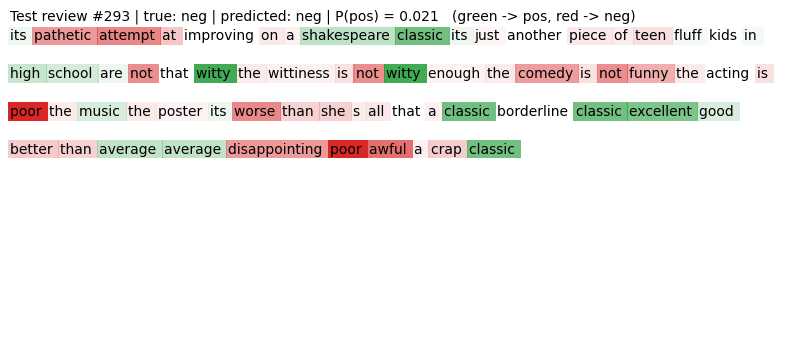

Top words: [(np.str_('poor'), -0.0860201499283462), (np.str_('witty'), 0.07165812661154705), (np.str_('awful'), -0.057381598031232536), (np.str_('classic'), 0.053021987061968076), (np.str_('excellent'), 0.049264451774433136), (np.str_('attempt'), -0.04778199909749702), (np.str_('worse'), -0.04645132763095177), (np.str_('not'), -0.044890345637062186)]


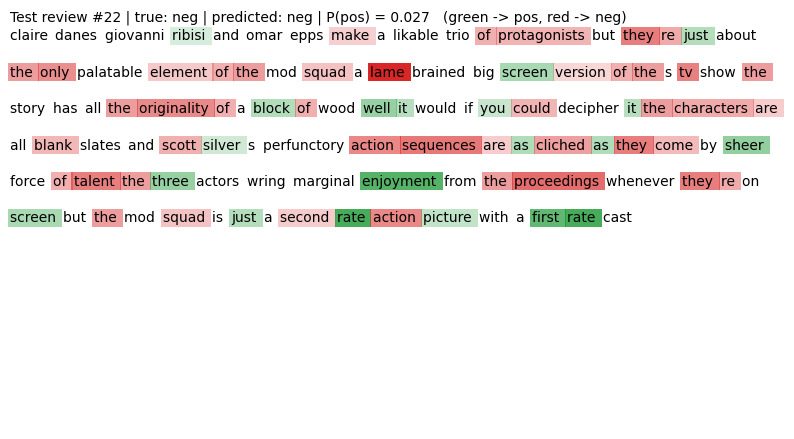

Top words: [(np.str_('lame'), -0.049664069492578365), (np.str_('rate'), 0.04017496928976595), (np.str_('enjoyment'), 0.0367420048957102), (np.str_('first'), 0.034237632818203856), (np.str_('proceedings'), -0.033757425057188144), (np.str_('sequences'), -0.030935864932724693), (np.str_('they'), -0.029532177123808033), (np.str_('talent'), -0.029387344658880054)]


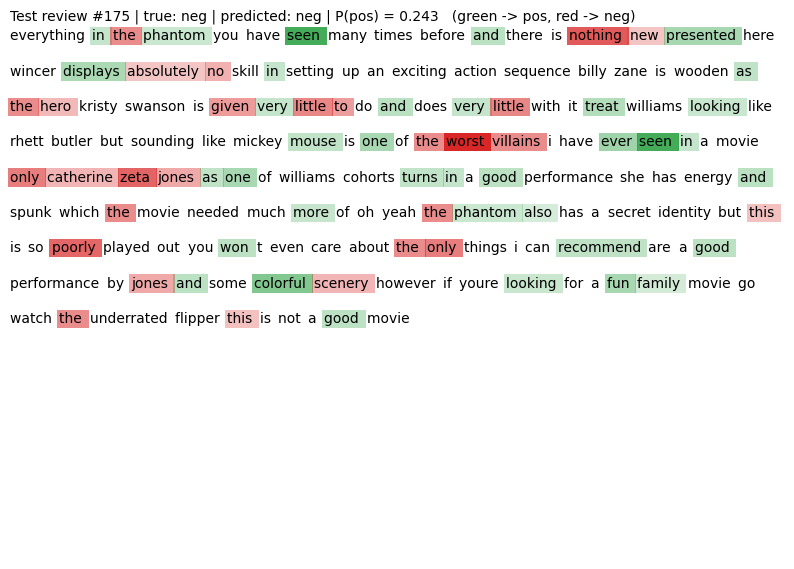

Top words: [(np.str_('worst'), -0.14300150585998467), (np.str_('seen'), 0.11648713618646168), (np.str_('nothing'), -0.10948415606434812), (np.str_('zeta'), -0.1020528855384712), (np.str_('poorly'), -0.10077968973266567), (np.str_('only'), -0.08589530485438014), (np.str_('little'), -0.07971632016601238), (np.str_('colorful'), 0.07755923133371688)]
Best config: {'layers': 1, 'hidden': 128, 'dropout': 0.6, 'lr': 0.0003}
Best epoch: 23 | K best epochs: [19, 20, 22, 23, 24]
Parameters in the MLP: 1280386


In [24]:

# ===== CELL 8: LIME heat-maps for the MLP =====

from lime.lime_text import LimeTextExplainer
import math

def predict_texts(texts):
    # LIME gives us perturbed raw texts; we preprocess, vectorize and ask the MLP
    cleaned = [preprocess(t) for t in texts]
    X = sparse_to_tensor(vectorizer.transform(cleaned))
    return predict_proba(single_model, X)          # columns: [neg, pos]

explainer = LimeTextExplainer(class_names=class_names, random_state=SEED)


def draw_heatmap(text, weights, title, path):
    """Colour every word of the text by its LIME weight for the class 'pos'.
    Green pushes towards pos, red pushes towards neg; stronger colour = larger effect."""
    words = text.split()
    max_w = max([abs(w) for w in weights.values()] + [1e-9])
    n_lines = math.ceil(len(words) / 13) + 1
    fig, ax = plt.subplots(figsize=(10, 0.42 * n_lines + 1.0))
    ax.axis('off')
    ax.set_title(title, fontsize=10, loc='left')
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    inv = ax.transAxes.inverted()
    line_h = 1.0 / (n_lines + 1)
    x, y = 0.0, 1.0
    for word in words:
        w = weights.get(word, 0.0)
        alpha = min(abs(w) / max_w, 1.0)
        color = (0.10, 0.60, 0.20, alpha) if w > 0 else (0.85, 0.15, 0.15, alpha)
        t = ax.text(x, y, word + ' ', fontsize=10, va='top', transform=ax.transAxes,
                    bbox=dict(facecolor=color, edgecolor='none', pad=1.5))
        box = t.get_window_extent(renderer).transformed(inv)
        if box.x1 > 1.0 and x > 0:                 # wrap to the next line
            x, y = 0.0, y - line_h
            t.set_position((x, y))
            box = t.get_window_extent(renderer).transformed(inv)
        x = box.x1 + 0.004
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()


# Short test reviews (60-160 words) so that the whole text fits in one picture
test_probs = predict_proba(single_model, Xte_t)
test_pred = labels_from_probs(test_probs)
short = [i for i, d in enumerate(X_test) if 60 <= len(d.split()) <= 160]

correct_idx = sorted([i for i in short if test_pred[i] == y_test[i]],
                     key=lambda i: -test_probs[i].max())[:3]
wrong_idx = sorted([i for i in short if test_pred[i] != y_test[i]],
                   key=lambda i: -test_probs[i].max())[:3]

for kind, indices in [('correct', correct_idx), ('wrong', wrong_idx)]:
    for rank, i in enumerate(indices, start=1):
        exp = explainer.explain_instance(X_test[i], predict_texts, num_features=40,
                                         num_samples=3000, labels=(1,))
        weights = dict(exp.as_list(label=1))
        title = ('Test review #' + str(i) + ' | true: ' + y_test[i] + ' | predicted: ' + test_pred[i]
                 + ' | P(pos) = ' + str(round(float(test_probs[i][1]), 3))
                 + '   (green -> pos, red -> neg)')
        draw_heatmap(X_test[i], weights, title, 'lime_' + kind + '_' + str(rank) + '.png')
        print('Top words:', sorted(weights.items(), key=lambda kv: -abs(kv[1]))[:8])


# ===== CELL 9: statistics to paste back (optional but handy) =====

print("Best config:", best_cfg)
print("Best epoch:", best_epoch, "| K best epochs:", sorted(c[1] for c in best_ckpts))
print("Parameters in the MLP:", sum(p.numel() for p in single_model.parameters()))
